<a href="https://colab.research.google.com/github/papoochu/student-ai-learning-analysis/blob/main/notebooks/lsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Load the same StudyChat dataset used for LDA and NMF
import pandas as pd
import numpy as np

# Public Hugging Face dataset; if access requires authentication,
# uncomment the two lines below and log in before re-running.
from huggingface_hub import login
login()

df = pd.read_json(
    "hf://datasets/wmcnicho/StudyChat/data.jsonl",
    lines=True
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (16851, 13)
Columns: ['prompt', 'response', 'topic', 'messages', 'timestamp', 'chatId', 'userId', 'interactionCount', 'chatTitle', 'chatStartTime', 'chatTotalInteractionCount', 'llm_label', 'semester']


In [2]:

# Step 2: Clean and preprocess StudyChat prompts
# Match the LDA/NMF preprocessing pipeline

import pandas as pd
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Keep prompts with actual text
modeling_corpus = df.copy()

modeling_corpus = modeling_corpus.dropna(subset=["prompt"])
modeling_corpus = modeling_corpus[
    modeling_corpus["prompt"].astype(str).str.strip() != ""
].copy()

# Exclude very long prompts (more than 1,000 words)
word_counts = modeling_corpus["prompt"].astype(str).str.split().str.len()
modeling_corpus = modeling_corpus[word_counts <= 1000].copy()

modeling_corpus = modeling_corpus.reset_index(drop=True)

stop_words_v2 = set(ENGLISH_STOP_WORDS)

def preprocess_text_v2(text):
    text = str(text).lower()

    # Preserve programming identifiers and underscores
    tokens = re.findall(
        r"\b[a-z_][a-z0-9_]*\b",
        text
    )

    # Remove English stop words and very short tokens
    tokens = [
        word for word in tokens
        if word not in stop_words_v2 and len(word) > 2
    ]

    return " ".join(tokens)

modeling_corpus["processed_text_v2"] = (
    modeling_corpus["prompt"].apply(preprocess_text_v2)
)

print("Original interactions:", len(df))
print("Prompts after cleaning:", len(modeling_corpus))
print("Unique students:", modeling_corpus["userId"].nunique())
print(
    "Empty prompts after preprocessing:",
    (modeling_corpus["processed_text_v2"] == "").sum()
)

display(
    modeling_corpus[
        ["prompt", "processed_text_v2"]
    ].head(3)
)


Original interactions: 16851
Prompts after cleaning: 16597
Unique students: 203
Empty prompts after preprocessing: 150


,prompt,processed_text_v2
0,"cross validation tests it on multiple sets, so...",cross validation tests multiple sets does rand...
1,### Report on findings/significance for Polyno...,report findings significance polynomial regres...
2,what is KCL or KCI,kcl kci


In [3]:

# Step 3: Create TF-IDF matrix for LSA
# Match the NMF vectorizer settings

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vect = TfidfVectorizer(
    max_df=0.8,
    min_df=5,
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf = tfidf_vect.fit_transform(
    modeling_corpus["processed_text_v2"].fillna("")
)

feature_names = tfidf_vect.get_feature_names_out()

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Number of documents:", X_tfidf.shape[0])
print("Vocabulary size:", X_tfidf.shape[1])
print("Nonzero entries:", X_tfidf.nnz)


TF-IDF matrix shape: (16597, 5000)
Number of documents: 16597
Vocabulary size: 5000
Nonzero entries: 544703


In [4]:

# Step 4: Train baseline LSA model with 5 components

from sklearn.decomposition import TruncatedSVD
import pandas as pd
import numpy as np

lsa_5 = TruncatedSVD(
    n_components=5,
    n_iter=10,
    random_state=42
)

# Document-component matrix
X_lsa_5 = lsa_5.fit_transform(X_tfidf)

print("LSA model trained successfully!")
print("Document-component matrix:", X_lsa_5.shape)
print("Component-term matrix:", lsa_5.components_.shape)

print(
    "Total explained variance:",
    round(lsa_5.explained_variance_ratio_.sum(), 4)
)

# Show the top 10 highest-weighted words per component
feature_names = tfidf_vect.get_feature_names_out()

topics = []

for topic_id, component in enumerate(lsa_5.components_):
    top_indices = np.argsort(component)[-10:][::-1]

    topics.append({
        "Component": topic_id + 1,
        "Top Words": ", ".join(feature_names[top_indices])
    })

lsa_5_topics_df = pd.DataFrame(topics)

display(lsa_5_topics_df)


LSA model trained successfully!
Document-component matrix: (16597, 5)
Component-term matrix: (5, 5000)
Total explained variance: 0.0508


,Component,Top Words
0,1,"model, char, node, self, sequence, tables, use..."
1,2,"node, char, children, prefix, self, node child..."
2,3,"tables, sequence, probability, frequency table..."
3,4,"count, query, target, sql, pandas, target coun..."
4,5,"query, sql, target, score, sql query, select t..."


In [6]:
# Step 5: Compare LSA component counts

!pip install -q gensim

import numpy as np
import pandas as pd

from sklearn.decomposition import TruncatedSVD
from gensim.models.coherencemodel import CoherenceModel
from gensim.corpora import Dictionary

# Prepare documents for coherence evaluation
tokenized_docs = [
    text.split()
    for text in modeling_corpus["processed_text_v2"].fillna("")
]

dictionary = Dictionary(tokenized_docs)
bow_corpus = [
    dictionary.doc2bow(doc)
    for doc in tokenized_docs
]

feature_names = tfidf_vect.get_feature_names_out()

lsa_results = []
lsa_models = {}

for k in [5, 8, 11, 15]:

    model = TruncatedSVD(
        n_components=k,
        n_iter=10,
        random_state=42
    )

    model.fit(X_tfidf)
    lsa_models[k] = model

    topics = []

    for component in model.components_:
        ranked_indices = np.argsort(component)[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    lsa_results.append({
        "Components": k,
        "Explained Variance": model.explained_variance_ratio_.sum(),
        "UMass Coherence": coherence
    })

lsa_results_df = pd.DataFrame(lsa_results)

display(lsa_results_df.round(4))

,Components,Explained Variance,UMass Coherence
0,5,0.0508,-1.3382
1,8,0.0749,-1.7634
2,11,0.0960,-1.9635
3,15,0.1203,-2.3893


In [7]:

# Step 6: Inspect positive and negative LSA keywords

import numpy as np
import pandas as pd

lsa_5 = lsa_models[5]
feature_names = tfidf_vect.get_feature_names_out()

component_details = []

for component_id, component in enumerate(lsa_5.components_):

    positive_indices = np.argsort(component)[-10:][::-1]
    negative_indices = np.argsort(component)[:10]

    positive_words = ", ".join(
        feature_names[positive_indices]
    )

    negative_words = ", ".join(
        feature_names[negative_indices]
    )

    component_details.append({
        "Component": component_id + 1,
        "Positive Keywords": positive_words,
        "Negative Keywords": negative_words,
        "Explained Variance (%)": (
            lsa_5.explained_variance_ratio_[component_id] * 100
        )
    })

lsa_component_details_df = pd.DataFrame(component_details)

display(lsa_component_details_df.round(3))


,Component,Positive Keywords,Negative Keywords,Explained Variance (%)
0,1,"model, char, node, self, sequence, tables, use...","snatched cancelled, shook tea, cancelled glowe...",0.726
1,2,"node, char, children, prefix, self, node child...","score, model, dataset, use, data, pandas, skle...",1.214
2,3,"tables, sequence, probability, frequency table...","node, self, children, node children, prefix, w...",1.144
3,4,"count, query, target, sql, pandas, target coun...","score, model, sklearn, regression, report, use...",1.062
4,5,"query, sql, target, score, sql query, select t...","blood, columns, age, cell, dataset, column, ro...",0.931


k= 1 | Variance=0.73% | Coherence=-1.5528
k= 2 | Variance=1.94% | Coherence=-1.1411
k= 3 | Variance=3.08% | Coherence=-1.0163
k= 4 | Variance=4.15% | Coherence=-1.0891
k= 5 | Variance=5.08% | Coherence=-1.3382
k= 6 | Variance=5.97% | Coherence=-1.3407
k= 7 | Variance=6.74% | Coherence=-1.4848
k= 8 | Variance=7.49% | Coherence=-1.7634
k= 9 | Variance=8.23% | Coherence=-1.9077
k=10 | Variance=8.93% | Coherence=-1.9815
k=11 | Variance=9.60% | Coherence=-1.9635
k=12 | Variance=10.24% | Coherence=-2.1638
k=13 | Variance=10.86% | Coherence=-2.0783
k=14 | Variance=11.46% | Coherence=-2.3238
k=15 | Variance=12.03% | Coherence=-2.3893

Highest coherence: 3 components (-1.0163)


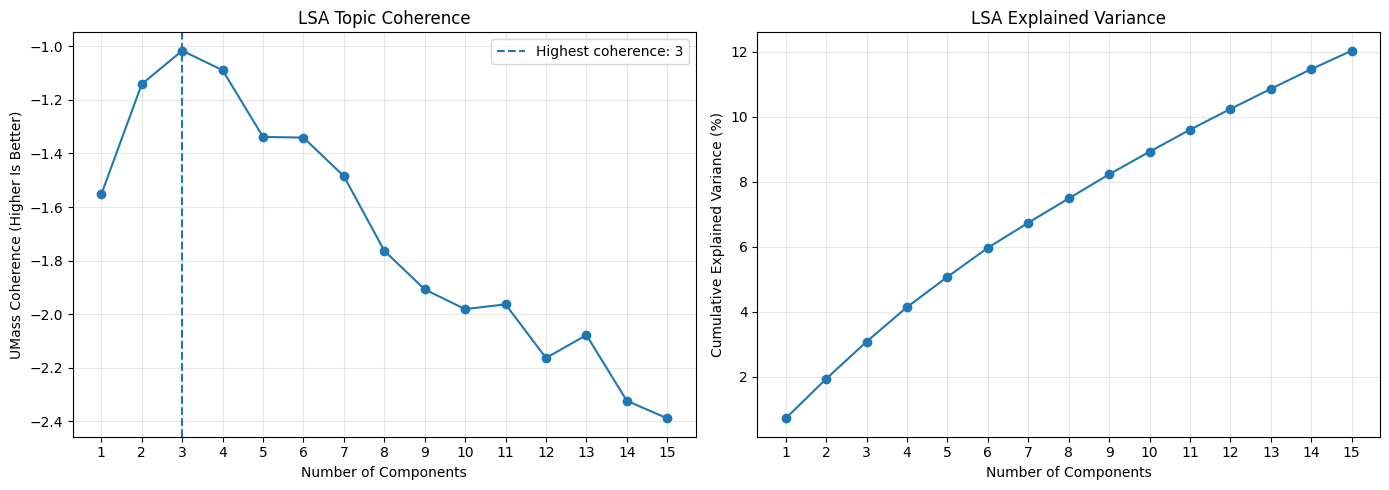

,Components,Explained Variance (%),UMass Coherence
0,1,0.7260,-1.5528
1,2,1.9404,-1.1411
2,3,3.0840,-1.0163
3,4,4.1459,-1.0891
4,5,5.0769,-1.3382
5,6,5.9701,-1.3407
6,7,6.7416,-1.4848
7,8,7.4875,-1.7634
8,9,8.2297,-1.9077
9,10,8.9259,-1.9815


In [8]:

# Step 7: Evaluate and graph LSA components from 1 to 15

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD
from gensim.models.coherencemodel import CoherenceModel

feature_names = tfidf_vect.get_feature_names_out()

lsa_results = []
lsa_models = {}

for k in range(1, 16):

    model = TruncatedSVD(
        n_components=k,
        n_iter=10,
        random_state=42
    )

    model.fit(X_tfidf)
    lsa_models[k] = model

    topics = []

    for component in model.components_:
        ranked_indices = np.argsort(component)[::-1]

        top_words = [
            feature_names[i]
            for i in ranked_indices
            if " " not in feature_names[i]
        ][:10]

        topics.append(top_words)

    coherence = CoherenceModel(
        topics=topics,
        corpus=bow_corpus,
        dictionary=dictionary,
        coherence="u_mass"
    ).get_coherence()

    lsa_results.append({
        "Components": k,
        "Explained Variance (%)":
            model.explained_variance_ratio_.sum() * 100,
        "UMass Coherence": coherence
    })

    print(
        f"k={k:2d} | "
        f"Variance={model.explained_variance_ratio_.sum()*100:.2f}% | "
        f"Coherence={coherence:.4f}"
    )

lsa_results_df = pd.DataFrame(lsa_results)

# Identify the highest-coherence configuration
best_row = lsa_results_df.loc[
    lsa_results_df["UMass Coherence"].idxmax()
]

print(
    f"\nHighest coherence: "
    f"{int(best_row['Components'])} components "
    f"({best_row['UMass Coherence']:.4f})"
)

# Plot both evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    lsa_results_df["Components"],
    lsa_results_df["UMass Coherence"],
    marker="o"
)
axes[0].axvline(
    best_row["Components"],
    linestyle="--",
    label=f"Highest coherence: {int(best_row['Components'])}"
)
axes[0].set_title("LSA Topic Coherence")
axes[0].set_xlabel("Number of Components")
axes[0].set_ylabel("UMass Coherence (Higher Is Better)")
axes[0].set_xticks(range(1, 16))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    lsa_results_df["Components"],
    lsa_results_df["Explained Variance (%)"],
    marker="o"
)
axes[1].set_title("LSA Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance (%)")
axes[1].set_xticks(range(1, 16))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(lsa_results_df.round(4))


In [9]:

# Step 8: Inspect the best-coherence LSA model (3 components)

import numpy as np
import pandas as pd

lsa_3 = lsa_models[3]
feature_names = tfidf_vect.get_feature_names_out()

component_details = []

for component_id, component in enumerate(lsa_3.components_):

    positive_indices = np.argsort(component)[-12:][::-1]
    negative_indices = np.argsort(component)[:12]

    component_details.append({
        "Component": component_id + 1,
        "Top Positive Words": ", ".join(
            feature_names[positive_indices]
        ),
        "Top Negative Words": ", ".join(
            feature_names[negative_indices]
        ),
        "Explained Variance (%)": round(
            100 * lsa_3.explained_variance_ratio_[component_id],
            3
        )
    })

lsa_3_details_df = pd.DataFrame(component_details)

display(lsa_3_details_df)


,Component,Top Positive Words,Top Negative Words,Explained Variance (%)
0,1,"model, char, node, self, sequence, tables, use...","snatched cancelled, shook tea, cancelled glowe...",0.726
1,2,"node, char, children, prefix, self, node child...","score, model, dataset, use, data, pandas, skle...",1.214
2,3,"tables, sequence, probability, frequency table...","node, self, children, node children, prefix, w...",1.144


In [10]:

# Step 9: Inspect representative prompts for LSA components

import numpy as np
import pandas as pd

lsa_3 = lsa_models[3]

# Transform prompts into LSA component scores
document_scores = lsa_3.transform(X_tfidf)

samples = []

for component_id in range(3):

    scores = document_scores[:, component_id]

    # First component: positive examples only
    # Other components: inspect both positive and negative sides
    directions = ["Positive"] if component_id == 0 else [
        "Positive", "Negative"
    ]

    for direction in directions:

        if direction == "Positive":
            indices = np.argsort(scores)[-5:][::-1]
        else:
            indices = np.argsort(scores)[:5]

        for idx in indices:
            samples.append({
                "Component": component_id + 1,
                "Direction": direction,
                "Score": round(float(scores[idx]), 4),
                "Prompt": modeling_corpus.iloc[idx]["prompt"][:250]
            })

lsa_samples_df = pd.DataFrame(samples)

display(lsa_samples_df)


,Component,Direction,Score,Prompt
0,1,Positive,0.4945,import pandas as pd\n\ndef create_frequency_ta...
1,1,Positive,0.4924,my code: from utilities import read_file\n\nde...
2,1,Positive,0.4907,Why is this code: from collections import defa...
3,1,Positive,0.4888,is this code right (def create_frequency_table...
4,1,Positive,0.4867,NgramAutocomplete.py is the core file where yo...
5,2,Positive,0.5112,take this code and complete the suggest_dfs an...
6,2,Positive,0.5081,from collections import deque\nimport heapq\ni...
7,2,Positive,0.5056,from collections import deque\nimport heapq\ni...
8,2,Positive,0.5055,from collections import deque\nimport heapq\ni...
9,2,Positive,0.5049,This is autocomplete.py:\nfrom collections imp...


In [11]:

# Step 10: Measure repetition among strongest LSA prompts

import numpy as np
import pandas as pd

results = []

normalized_prompts = (
    modeling_corpus["prompt"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

for component_id in range(3):

    scores = document_scores[:, component_id]

    directions = (
        ["Positive"] if component_id == 0
        else ["Positive", "Negative"]
    )

    for direction in directions:

        if direction == "Positive":
            indices = np.argsort(scores)[-100:]
        else:
            indices = np.argsort(scores)[:100]

        selected_prompts = normalized_prompts.iloc[indices]

        total = len(selected_prompts)
        unique = selected_prompts.nunique()

        results.append({
            "Component": component_id + 1,
            "Direction": direction,
            "Prompts Examined": total,
            "Unique Prompts": unique,
            "Duplicate Rate (%)": 100 * (total - unique) / total
        })

lsa_duplicate_df = pd.DataFrame(results)

display(lsa_duplicate_df.round(2))


,Component,Direction,Prompts Examined,Unique Prompts,Duplicate Rate (%)
0,1,Positive,100,98,2.0
1,2,Positive,100,99,1.0
2,2,Negative,100,87,13.0
3,3,Positive,100,80,20.0
4,3,Negative,100,100,0.0


In [12]:

# Step 11: Student coverage of strongest LSA patterns

import numpy as np
import pandas as pd

results = []

for component_id in range(3):

    scores = document_scores[:, component_id]

    directions = (
        ["Positive"] if component_id == 0
        else ["Positive", "Negative"]
    )

    for direction in directions:

        if direction == "Positive":
            indices = np.argsort(scores)[-100:]
        else:
            indices = np.argsort(scores)[:100]

        selected = modeling_corpus.iloc[indices]

        student_counts = selected["userId"].value_counts()

        results.append({
            "Component": component_id + 1,
            "Direction": direction,
            "Prompts": len(selected),
            "Unique Students": selected["userId"].nunique(),
            "Largest Student Share (%)": (
                100 * student_counts.iloc[0] / len(selected)
            ),
            "Median Prompts per Student": student_counts.median()
        })

student_coverage_df = pd.DataFrame(results)

display(student_coverage_df.round(2))


,Component,Direction,Prompts,Unique Students,Largest Student Share (%),Median Prompts per Student
0,1,Positive,100,48,19.0,1.0
1,2,Positive,100,52,7.0,1.0
2,2,Negative,100,67,6.0,1.0
3,3,Positive,100,58,11.0,1.0
4,3,Negative,100,50,6.0,1.0


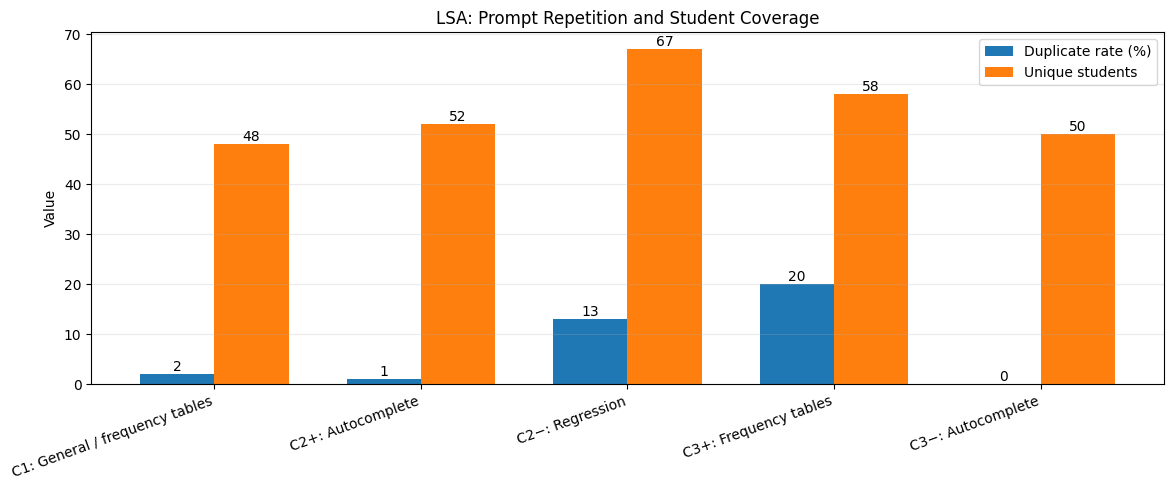

In [13]:

# Step 12: Visualize duplicate rates and student coverage

import matplotlib.pyplot as plt
import numpy as np

labels = [
    "C1: General / frequency tables",
    "C2+: Autocomplete",
    "C2−: Regression",
    "C3+: Frequency tables",
    "C3−: Autocomplete"
]

duplicate_rates = lsa_duplicate_df["Duplicate Rate (%)"].values
student_counts = student_coverage_df["Unique Students"].values

x = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5))

bars1 = ax.bar(
    x - width / 2,
    duplicate_rates,
    width,
    label="Duplicate rate (%)"
)

bars2 = ax.bar(
    x + width / 2,
    student_counts,
    width,
    label="Unique students"
)

ax.set_title(
    "LSA: Prompt Repetition and Student Coverage"
)
ax.set_ylabel("Value")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars1, fmt="%.0f")
ax.bar_label(bars2, fmt="%.0f")

plt.tight_layout()
plt.show()


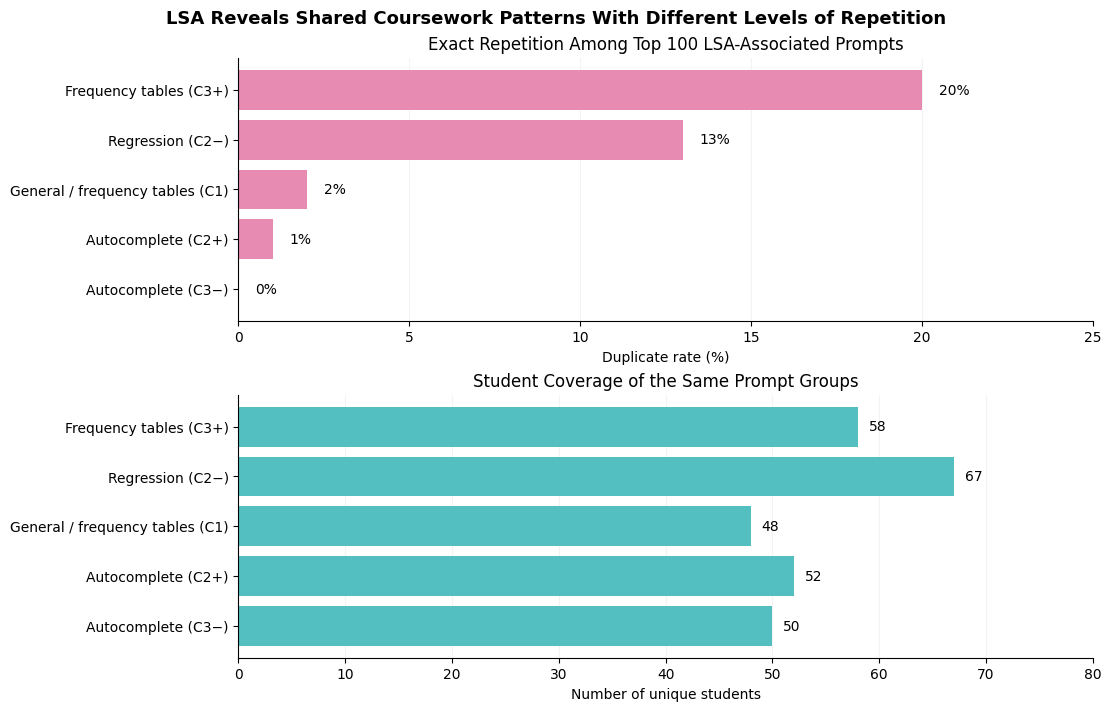

In [14]:

# Step 13: Improved visualization of LSA findings

import matplotlib.pyplot as plt
import numpy as np

labels = [
    "Frequency tables (C3+)",
    "Regression (C2−)",
    "General / frequency tables (C1)",
    "Autocomplete (C2+)",
    "Autocomplete (C3−)"
]

# Ordered from highest to lowest duplicate rate
duplicate_rates = [20, 13, 2, 1, 0]
unique_students = [58, 67, 48, 52, 50]

y = np.arange(len(labels))

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharey=True,
    gridspec_kw={"height_ratios": [1, 1]},
    layout="constrained"
)

# Chart 1: Duplicate rates
axes[0].barh(y, duplicate_rates, color="#E78BB2")
axes[0].set_title(
    "Exact Repetition Among Top 100 LSA-Associated Prompts"
)
axes[0].set_xlabel("Duplicate rate (%)")
axes[0].set_xlim(0, 25)
axes[0].invert_yaxis()

for i, value in enumerate(duplicate_rates):
    axes[0].text(value + 0.5, i, f"{value}%", va="center")

# Chart 2: Student coverage
axes[1].barh(y, unique_students, color="#54BFC0")
axes[1].set_title(
    "Student Coverage of the Same Prompt Groups"
)
axes[1].set_xlabel("Number of unique students")
axes[1].set_xlim(0, 80)

for i, value in enumerate(unique_students):
    axes[1].text(value + 1, i, str(value), va="center")

for ax in axes:
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "LSA Reveals Shared Coursework Patterns With Different Levels of Repetition",
    fontsize=13,
    fontweight="bold"
)

plt.show()


## LSA Results and Interpretation

### Model Selection

Latent Semantic Analysis (LSA) was applied to 16,597 preprocessed StudyChat prompts using TF-IDF and Truncated Singular Value Decomposition (TruncatedSVD). The same TF-IDF settings used for NMF were retained to support comparison.

Models with 1–15 components were evaluated using UMass topic coherence and cumulative explained variance.

- **Highest topic coherence:** 3 components (approximately −1.02).
- **Explained variance at 3 components:** Approximately 3.08%.
- **Explained variance at 15 components:** Approximately 12.03%.

Although explained variance increased with additional components, topic coherence generally decreased. The three-component model was therefore selected provisionally based on its highest observed coherence.

### Component Interpretation

The three-component model primarily identified recurring programming and coursework-related vocabulary patterns:

1. **Component 1:** Broad programming vocabulary, with its strongest prompts involving n-gram frequency-table implementations.
2. **Component 2:** A contrast between autocomplete/tree implementations (positive weights) and regression assignments (negative weights).
3. **Component 3:** A contrast between n-gram frequency-table implementations (positive weights) and autocomplete/tree implementations (negative weights).

Unlike LDA and NMF, LSA components can have positive and negative word weights. Consequently, individual components may distinguish between subjects rather than represent a single independent topic.

### Duplicate Prompts and Student Coverage

To investigate whether repeated coursework influenced LSA, the 100 highest-scoring prompts for each component direction were examined.

| Component direction | Exact duplicate rate | Unique students |
|---|---:|---:|
| Component 1: Positive | 2% | 48 |
| Component 2: Positive (autocomplete) | 1% | 52 |
| Component 2: Negative (regression) | 13% | 67 |
| Component 3: Positive (frequency tables) | 20% | 58 |
| Component 3: Negative (autocomplete) | 0% | 50 |

These patterns occurred across dozens of students, indicating that they were not exclusively driven by one highly active participant.

Importantly, some patterns contained highly similar programming content despite having very few exact duplicate prompts. This suggests that shared coursework may generate different student questions containing similar code structures or assignment terminology.

Other patterns, particularly frequency-table and regression assignments, exhibited greater exact repetition.

### Comparison With LDA and NMF

The models selected different numbers of topics or components based on their highest measured UMass coherence:

- **LDA:** 11 topics.
- **NMF:** 5 topics.
- **LSA:** 3 components.

LDA produced a more detailed breakdown of technical vocabulary, while NMF identified broader coursework-related themes. LSA primarily captured prominent vocabulary patterns and contrasts between assignment contexts.

These differences may reflect each model's mathematical assumptions, input representation, and sensitivity to recurring coursework terminology. The selected topic counts should not be interpreted as the definitive number of educational themes in the dataset.

### Implications for Student-AI Learning Research

LSA provides additional evidence that topic-modeling results may reflect the structure of shared coursework rather than distinct learning behaviors.

**Topics containing many duplicate prompts may reflect assignment-driven AI use, while topics containing more varied prompts may reflect individualized help-seeking.** However, prompt diversity alone cannot establish how students engage with AI responses.

For example, students working on the same assignment may submit similar code while pursuing different goals, such as debugging, requesting explanations, or completing an implementation.

Therefore, topic modeling is useful for identifying **what students discuss with AI**, but understanding **how they use AI to support learning** requires conversation-level analysis.

### Limitations

- The three-component LSA model explained only approximately 3.08% of TF-IDF variance.
- UMass coherence was calculated using the training corpus and top positive component keywords.
- LSA components do not necessarily correspond to independent, interpretable educational topics.
- Exact duplicate detection does not identify semantically similar prompts or confirm copying from assignments.
- Student coverage and duplicate rates were measured only among the 100 strongest prompts per component direction.
- Topic models cannot independently identify passive review, direct questioning, or strategic dialogue.

**Overall conclusion:** LSA identified recurring assignment-related language patterns across multiple students, supporting the interpretation that shared coursework influences the vocabulary of student-AI interactions. However, these patterns should not be mistaken for direct evidence of students' learning strategies.